In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_root = Path.home() / "Documents" / "airline-delay-reliability-analysis"

monthly_dir = project_root / "data" / "processed" / "monthly"
figures_dir = project_root / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)

parquet_files = sorted(
    monthly_dir.glob("flights_2025_*.parquet")
)

intervention_columns = [
    "FlightDate",
    "Month",
    "DayOfWeek",
    "Marketing_Airline_Network",
    "Operating_Airline",
    "Origin",
    "Dest",
    "CRSDepTime",
    "ArrDelayMinutes",
    "ArrDel15",
    "Cancelled",
    "Diverted",
    "CarrierDelay",
    "WeatherDelay",
    "NASDelay",
    "SecurityDelay",
    "LateAircraftDelay"
]

monthly_dfs = []

for file in parquet_files:
    month_df = pd.read_parquet(
        file,
        columns=intervention_columns,
        engine="pyarrow"
    )
    monthly_dfs.append(month_df)

intervention_df = pd.concat(
    monthly_dfs,
    ignore_index=True
)

memory_mb = (
    intervention_df.memory_usage(deep=True).sum()
    / 1024**2
)

print(f"Rows: {len(intervention_df):,}")
print(f"Columns: {intervention_df.shape[1]}")
print(f"Memory usage: {memory_mb:.2f} MB")

print()
print("Airlines:")
print(
    intervention_df["Marketing_Airline_Network"]
    .value_counts()
)

print()
print("Date range:")
print(
    intervention_df["FlightDate"].min(),
    "to",
    intervention_df["FlightDate"].max()
)

Rows: 4,518,993
Columns: 17
Memory usage: 629.21 MB

Airlines:
Marketing_Airline_Network
AA    1702832
DL    1470316
UA    1345845
Name: count, dtype: int64

Date range:
2025-01-01 00:00:00 to 2025-12-31 00:00:00


In [2]:
delay_cause_columns = [
    "CarrierDelay",
    "WeatherDelay",
    "NASDelay",
    "SecurityDelay",
    "LateAircraftDelay"
]

cause_totals = (
    intervention_df[delay_cause_columns]
    .sum()
)

total_attributed_delay = cause_totals.sum()

actionable_delay_minutes = (
    cause_totals["CarrierDelay"]
    + cause_totals["LateAircraftDelay"]
)

actionable_share_pct = (
    actionable_delay_minutes
    / total_attributed_delay
    * 100
)

external_delay_minutes = (
    cause_totals["WeatherDelay"]
    + cause_totals["NASDelay"]
    + cause_totals["SecurityDelay"]
)

external_share_pct = (
    external_delay_minutes
    / total_attributed_delay
    * 100
)

print(f"Total attributed delay minutes: {total_attributed_delay:,.0f}")

print()
print(
    f"Operationally actionable delay minutes: "
    f"{actionable_delay_minutes:,.0f}"
)

print(
    f"Operationally actionable share: "
    f"{actionable_share_pct:.2f}%"
)

print()
print(
    f"External / system delay minutes: "
    f"{external_delay_minutes:,.0f}"
)

print(
    f"External / system share: "
    f"{external_share_pct:.2f}%"
)

print()
print("Cause breakdown:")
print(cause_totals.sort_values(ascending=False))

Total attributed delay minutes: 76,925,980

Operationally actionable delay minutes: 54,619,827
Operationally actionable share: 71.00%

External / system delay minutes: 22,306,153
External / system share: 29.00%

Cause breakdown:
LateAircraftDelay    28338074.0
CarrierDelay         26281753.0
NASDelay             16324526.0
WeatherDelay          5920532.0
SecurityDelay           61095.0
dtype: float64


In [3]:
core_airports = [
    "ATL", "DFW", "DEN", "ORD",
    "CLT", "MIA", "PHX",
    "DTW", "MSP", "SLC",
    "JFK", "LGA",
    "IAH", "EWR", "SFO", "LAX"
]

intervention_df["actionable_delay_minutes"] = (
    intervention_df["CarrierDelay"].fillna(0)
    + intervention_df["LateAircraftDelay"].fillna(0)
)

intervention_df["attributed_delay_minutes"] = (
    intervention_df[delay_cause_columns]
    .fillna(0)
    .sum(axis=1)
)

core_airport_df = intervention_df[
    intervention_df["Origin"].isin(core_airports)
].copy()

airport_intervention = (
    core_airport_df
    .groupby("Origin")
    .agg(
        scheduled_departures=("Origin", "size"),
        completed_arrivals=("ArrDel15", "count"),
        delayed_arrivals=("ArrDel15", "sum"),
        total_arrival_delay_minutes=("ArrDelayMinutes", "sum"),
        actionable_delay_minutes=("actionable_delay_minutes", "sum"),
        attributed_delay_minutes=("attributed_delay_minutes", "sum")
    )
)

airport_intervention["delay_rate_pct"] = (
    airport_intervention["delayed_arrivals"]
    / airport_intervention["completed_arrivals"]
    * 100
)

airport_intervention["actionable_delay_intensity"] = (
    airport_intervention["actionable_delay_minutes"]
    / airport_intervention["completed_arrivals"]
    * 1000
)

airport_intervention["actionable_share_pct"] = (
    airport_intervention["actionable_delay_minutes"]
    / airport_intervention["attributed_delay_minutes"]
    * 100
)

airport_intervention[
    [
        "delay_rate_pct",
        "actionable_delay_intensity",
        "actionable_share_pct"
    ]
] = airport_intervention[
    [
        "delay_rate_pct",
        "actionable_delay_intensity",
        "actionable_share_pct"
    ]
].round(2)

airport_intervention = airport_intervention.sort_values(
    "actionable_delay_minutes",
    ascending=False
)

airport_intervention

,scheduled_departures,completed_arrivals,delayed_arrivals,total_arrival_delay_minutes,actionable_delay_minutes,attributed_delay_minutes,delay_rate_pct,actionable_delay_intensity,actionable_share_pct
Origin,,,,,,,,,
ORD,338620,331771,88045.0,7189867.0,4917193.0,6855454.0,26.54,14821.05,71.73
DFW,298451,289112,83349.0,6386312.0,4604472.0,6083828.0,28.83,15926.26,75.68
ATL,300059,294925,67589.0,4841343.0,3161473.0,4536418.0,22.92,10719.58,69.69
CLT,233136,228560,53041.0,3926332.0,2773163.0,3703862.0,23.21,12133.19,74.87
DEN,200911,198591,46457.0,3552201.0,2407172.0,3349977.0,23.39,12121.25,71.86
LGA,141003,135968,35472.0,2875531.0,1850159.0,2755810.0,26.09,13607.31,67.14
IAH,157107,154372,32343.0,2665532.0,1821815.0,2531288.0,20.95,11801.46,71.97
EWR,113239,109872,27831.0,2377205.0,1636807.0,2279554.0,25.33,14897.40,71.80
DTW,122607,120951,26770.0,2122107.0,1431395.0,2008486.0,22.13,11834.50,71.27


In [4]:
route_intervention = (
    intervention_df
    .groupby(["Origin", "Dest"])
    .agg(
        scheduled_flights=("Origin", "size"),
        completed_arrivals=("ArrDel15", "count"),
        delayed_arrivals=("ArrDel15", "sum"),
        total_arrival_delay_minutes=("ArrDelayMinutes", "sum"),
        actionable_delay_minutes=("actionable_delay_minutes", "sum"),
        attributed_delay_minutes=("attributed_delay_minutes", "sum")
    )
)

route_intervention = route_intervention[
    route_intervention["scheduled_flights"] >= 1000
].copy()

route_intervention["delay_rate_pct"] = (
    route_intervention["delayed_arrivals"]
    / route_intervention["completed_arrivals"]
    * 100
)

route_intervention["actionable_delay_intensity"] = (
    route_intervention["actionable_delay_minutes"]
    / route_intervention["completed_arrivals"]
    * 1000
)

route_intervention["actionable_share_pct"] = (
    route_intervention["actionable_delay_minutes"]
    / route_intervention["attributed_delay_minutes"]
    * 100
)

route_intervention["route"] = (
    route_intervention.index.get_level_values("Origin")
    + " → "
    + route_intervention.index.get_level_values("Dest")
)

route_intervention[
    [
        "delay_rate_pct",
        "actionable_delay_intensity",
        "actionable_share_pct"
    ]
] = route_intervention[
    [
        "delay_rate_pct",
        "actionable_delay_intensity",
        "actionable_share_pct"
    ]
].round(2)

route_intervention = (
    route_intervention
    .sort_values(
        "actionable_delay_minutes",
        ascending=False
    )
)

route_intervention[
    [
        "route",
        "scheduled_flights",
        "delay_rate_pct",
        "actionable_delay_minutes",
        "actionable_delay_intensity",
        "actionable_share_pct"
    ]
].head(25)

route  scheduled_flights  delay_rate_pct  \
Origin Dest                                                 
LGA    ORD   LGA → ORD              11086           30.07   
ORD    LGA   ORD → LGA              11085           29.93   
IAH    DFW   IAH → DFW               6334           26.14   
ORD    DCA   ORD → DCA               6758           30.21   
DFW    ORD   DFW → ORD               6128           29.54   
       IAH   DFW → IAH               6335           30.48   
ORD    DFW   ORD → DFW               6120           28.02   
LAX    DFW   LAX → DFW               5415           23.75   
ORD    MSP   ORD → MSP               6224           28.20   
MIA    ATL   MIA → ATL               5236           28.82   
DFW    SAT   DFW → SAT               4503           33.46   
LGA    DFW   LGA → DFW               6308           30.61   
DFW    LGA   DFW → LGA               6309           31.29   
BOS    ORD   BOS → ORD               6716           26.95   
ORD    MKE   ORD → MKE               4710           31.58   
EWR    ATL   EWR → ATL               5021           28.50   
LGA    MIA   LGA → MIA               5430           29.40   
ORD    STL   ORD → STL               4622           27.21   
AUS    DFW   AUS → DFW               4818           26.28   
ORD    DTW   ORD → DTW               5997           24.74   
LAX    JFK   LAX → JFK               6584           18.92   
DEN    DFW   DEN → DFW               5019           26.89   
MKE    ORD   MKE → ORD               4709           30.50   
DCA    ORD   DCA → ORD               6761           23.71   
MCO    ATL   MCO → ATL               5374           24.45   

             actionable_delay_minutes  actionable_delay_intensity  \
Origin Dest                                                         
LGA    ORD                   182975.0                    16998.79   
ORD    LGA                   170212.0                    15854.32   
IAH    DFW                   113271.0                    18526.50   
ORD    DCA                   105620.0                    16139.98   
DFW    ORD                   101222.0                    16989.26   
       IAH                   100278.0                    16439.02   
ORD    DFW                    99901.0                    16832.52   
LAX    DFW                    98975.0                    18745.27   
ORD    MSP                    98779.0                    16093.03   
MIA    ATL                    98698.0                    19164.66   
DFW    SAT                    95914.0                    22105.09   
LGA    DFW                    95725.0                    15838.02   
DFW    LGA                    94763.0                    15681.45   
BOS    ORD                    94140.0                    14278.78   
ORD    MKE                    92282.0                    20193.00   
EWR    ATL                    92087.0                    18881.89   
LGA    MIA                    91809.0                    17368.33   
ORD    STL                    90246.0                    19917.46   
AUS    DFW                    88576.0                    19097.89   
ORD    DTW                    87498.0                    14895.81   
LAX    JFK                    87108.0                    13421.88   
DEN    DFW                    86730.0                    17710.84   
MKE    ORD                    86246.0                    18802.27   
DCA    ORD                    85282.0                    12986.45   
MCO    ATL                    84266.0                    15872.29   

             actionable_share_pct  
Origin Dest                        
LGA    ORD                  63.77  
ORD    LGA                  61.36  
IAH    DFW                  70.77  
ORD    DCA                  65.13  
DFW    ORD                  71.11  
       IAH                  70.63  
ORD    DFW                  70.63  
LAX    DFW                  83.17  
ORD    MSP                  73.43  
MIA    ATL                  77.46  
DFW    SAT                  83.73  
LGA    DFW                  63.07  
D

In [5]:
intervention_framework = pd.DataFrame([
    {
        "intervention": "Aircraft Rotation Recovery",
        "target_scope": "ORD, DFW, ATL, DEN, CLT, LGA and high-propagation rotations",
        "problem_addressed": "Late-aircraft delay propagation across consecutive aircraft rotations",
        "proposed_action": "Prioritize recovery of delayed inbound aircraft, proactively protect downstream rotations, and evaluate aircraft swaps or recovery resources when upstream delays exceed operational thresholds.",
        "primary_kpi": "Late Aircraft Delay Minutes",
        "secondary_kpi": "Propagation Rate",
        "evidence": "Previous-flight delay increased next-flight delay risk from 13.82% to 48.41%."
    },
    {
        "intervention": "Targeted Turnaround Support",
        "target_scope": "High-volume hubs such as ORD, DFW, ATL, CLT and DEN",
        "problem_addressed": "Carrier-related and late-aircraft delays at large operational nodes",
        "proposed_action": "Concentrate gate, ground-handling, baggage, fueling and turnaround recovery resources on flights with elevated disruption risk.",
        "primary_kpi": "Carrier Delay Minutes",
        "secondary_kpi": "Turnaround-related Delay Rate",
        "evidence": "Carrier and Late Aircraft delays represent 71.00% of attributed delay minutes."
    },
    {
        "intervention": "Route-Specific Schedule Buffer Review",
        "target_scope": "Repeated high-intensity routes such as DFW-SAT, ORD-MKE, ORD-STL, IAH-DFW and LAX-DFW",
        "problem_addressed": "Recurring route-level operational delay exposure",
        "proposed_action": "Review scheduled block and turnaround buffers on routes with persistently high actionable delay intensity while avoiding unnecessary system-wide schedule padding.",
        "primary_kpi": "Actionable Delay Intensity",
        "secondary_kpi": "Route Delay Rate",
        "evidence": "Several routes exceed 18,000-22,000 actionable delay minutes per 1,000 completed flights."
    },
    {
        "intervention": "High-Risk Flight Watchlist",
        "target_scope": "Flights flagged by the pre-flight XGBoost risk model",
        "problem_addressed": "Limited operational resources cannot be allocated equally to every flight",
        "proposed_action": "Use pre-flight risk scores to prioritize monitoring, recovery preparation and operational attention before disruption materializes.",
        "primary_kpi": "High-Risk Flight Delay Rate",
        "secondary_kpi": "Risk Lift",
        "evidence": "The final XGBoost model achieved a 1.32x risk lift on the December out-of-time test set."
    }
])

intervention_framework

,intervention,target_scope,problem_addressed,proposed_action,primary_kpi,secondary_kpi,evidence
0,Aircraft Rotation Recovery,"ORD, DFW, ATL, DEN, CLT, LGA and high-propagat...",Late-aircraft delay propagation across consecu...,Prioritize recovery of delayed inbound aircraf...,Late Aircraft Delay Minutes,Propagation Rate,Previous-flight delay increased next-flight de...
1,Targeted Turnaround Support,"High-volume hubs such as ORD, DFW, ATL, CLT an...",Carrier-related and late-aircraft delays at la...,"Concentrate gate, ground-handling, baggage, fu...",Carrier Delay Minutes,Turnaround-related Delay Rate,Carrier and Late Aircraft delays represent 71....
2,Route-Specific Schedule Buffer Review,Repeated high-intensity routes such as DFW-SAT...,Recurring route-level operational delay exposure,Review scheduled block and turnaround buffers ...,Actionable Delay Intensity,Route Delay Rate,"Several routes exceed 18,000-22,000 actionable..."
3,High-Risk Flight Watchlist,Flights flagged by the pre-flight XGBoost risk...,Limited operational resources cannot be alloca...,Use pre-flight risk scores to prioritize monit...,High-Risk Flight Delay Rate,Risk Lift,The final XGBoost model achieved a 1.32x risk ...


In [6]:
scenario_rates = [0.05, 0.10, 0.15]

network_scenarios = pd.DataFrame({
    "reduction_scenario": ["5%", "10%", "15%"],
    "reduction_rate": scenario_rates
})

network_scenarios["baseline_actionable_delay_minutes"] = (
    actionable_delay_minutes
)

network_scenarios["delay_minutes_saved"] = (
    network_scenarios["baseline_actionable_delay_minutes"]
    * network_scenarios["reduction_rate"]
)

network_scenarios["remaining_actionable_delay_minutes"] = (
    network_scenarios["baseline_actionable_delay_minutes"]
    - network_scenarios["delay_minutes_saved"]
)

network_scenarios[
    [
        "baseline_actionable_delay_minutes",
        "delay_minutes_saved",
        "remaining_actionable_delay_minutes"
    ]
] = network_scenarios[
    [
        "baseline_actionable_delay_minutes",
        "delay_minutes_saved",
        "remaining_actionable_delay_minutes"
    ]
].round(0)

network_scenarios

,reduction_scenario,reduction_rate,baseline_actionable_delay_minutes,delay_minutes_saved,remaining_actionable_delay_minutes
0,5%,0.05,54619827.0,2730991.0,51888836.0
1,10%,0.10,54619827.0,5461983.0,49157844.0
2,15%,0.15,54619827.0,8192974.0,46426853.0


In [7]:
priority_airports = [
    "ORD",
    "DFW",
    "ATL",
    "DEN",
    "CLT",
    "LGA"
]

targeted_baseline_minutes = (
    airport_intervention
    .loc[priority_airports, "actionable_delay_minutes"]
    .sum()
)

targeted_scenarios = pd.DataFrame({
    "reduction_scenario": ["5%", "10%", "15%"],
    "reduction_rate": scenario_rates
})

targeted_scenarios["target_airports"] = (
    "ORD, DFW, ATL, DEN, CLT, LGA"
)

targeted_scenarios["baseline_actionable_delay_minutes"] = (
    targeted_baseline_minutes
)

targeted_scenarios["delay_minutes_saved"] = (
    targeted_scenarios["baseline_actionable_delay_minutes"]
    * targeted_scenarios["reduction_rate"]
)

targeted_scenarios["remaining_actionable_delay_minutes"] = (
    targeted_scenarios["baseline_actionable_delay_minutes"]
    - targeted_scenarios["delay_minutes_saved"]
)

targeted_scenarios[
    [
        "baseline_actionable_delay_minutes",
        "delay_minutes_saved",
        "remaining_actionable_delay_minutes"
    ]
] = targeted_scenarios[
    [
        "baseline_actionable_delay_minutes",
        "delay_minutes_saved",
        "remaining_actionable_delay_minutes"
    ]
].round(0)

print(
    f"Targeted airport baseline actionable delay minutes: "
    f"{targeted_baseline_minutes:,.0f}"
)

targeted_scenarios

Targeted airport baseline actionable delay minutes: 19,713,632


,reduction_scenario,reduction_rate,target_airports,baseline_actionable_delay_minutes,delay_minutes_saved,remaining_actionable_delay_minutes
0,5%,0.05,"ORD, DFW, ATL, DEN, CLT, LGA",19713632.0,985682.0,18727950.0
1,10%,0.10,"ORD, DFW, ATL, DEN, CLT, LGA",19713632.0,1971363.0,17742269.0
2,15%,0.15,"ORD, DFW, ATL, DEN, CLT, LGA",19713632.0,2957045.0,16756587.0


In [8]:
cost_assumptions = {
    "Low ($20/min)": 20,
    "Base ($40/min)": 40,
    "High ($60/min)": 60
}

financial_rows = []

for _, row in network_scenarios.iterrows():
    for cost_label, cost_per_minute in cost_assumptions.items():
        financial_rows.append({
            "scope": "Network-wide",
            "reduction_scenario": row["reduction_scenario"],
            "delay_minutes_saved": row["delay_minutes_saved"],
            "cost_assumption": cost_label,
            "cost_per_minute": cost_per_minute,
            "estimated_operating_value": (
                row["delay_minutes_saved"]
                * cost_per_minute
            )
        })

for _, row in targeted_scenarios.iterrows():
    for cost_label, cost_per_minute in cost_assumptions.items():
        financial_rows.append({
            "scope": "Targeted 6 Airports",
            "reduction_scenario": row["reduction_scenario"],
            "delay_minutes_saved": row["delay_minutes_saved"],
            "cost_assumption": cost_label,
            "cost_per_minute": cost_per_minute,
            "estimated_operating_value": (
                row["delay_minutes_saved"]
                * cost_per_minute
            )
        })

financial_scenarios = pd.DataFrame(financial_rows)

financial_scenarios[
    "estimated_operating_value_millions"
] = (
    financial_scenarios["estimated_operating_value"]
    / 1_000_000
)

financial_scenarios[
    "estimated_operating_value_millions"
] = financial_scenarios[
    "estimated_operating_value_millions"
].round(2)

financial_scenarios[
    [
        "scope",
        "reduction_scenario",
        "delay_minutes_saved",
        "cost_assumption",
        "estimated_operating_value_millions"
    ]
]

,scope,reduction_scenario,delay_minutes_saved,cost_assumption,estimated_operating_value_millions
0,Network-wide,5%,2730991.0,Low ($20/min),54.62
1,Network-wide,5%,2730991.0,Base ($40/min),109.24
2,Network-wide,5%,2730991.0,High ($60/min),163.86
3,Network-wide,10%,5461983.0,Low ($20/min),109.24
4,Network-wide,10%,5461983.0,Base ($40/min),218.48
5,Network-wide,10%,5461983.0,High ($60/min),327.72
6,Network-wide,15%,8192974.0,Low ($20/min),163.86
7,Network-wide,15%,8192974.0,Base ($40/min),327.72
8,Network-wide,15%,8192974.0,High ($60/min),491.58
9,Targeted 6 Airports,5%,985682.0,Low ($20/min),19.71


In [9]:
base_reduction_rate = 0.10
base_cost_per_minute = 40

airport_base_case = (
    airport_intervention
    .loc[priority_airports]
    .copy()
)

airport_base_case["delay_minutes_saved_10pct"] = (
    airport_base_case["actionable_delay_minutes"]
    * base_reduction_rate
)

airport_base_case["estimated_value_usd"] = (
    airport_base_case["delay_minutes_saved_10pct"]
    * base_cost_per_minute
)

airport_base_case["estimated_value_millions"] = (
    airport_base_case["estimated_value_usd"]
    / 1_000_000
)

airport_base_case[
    [
        "actionable_delay_minutes",
        "delay_minutes_saved_10pct",
        "estimated_value_millions"
    ]
] = airport_base_case[
    [
        "actionable_delay_minutes",
        "delay_minutes_saved_10pct",
        "estimated_value_millions"
    ]
].round(2)

airport_base_case = airport_base_case[
    [
        "scheduled_departures",
        "delay_rate_pct",
        "actionable_delay_minutes",
        "actionable_delay_intensity",
        "delay_minutes_saved_10pct",
        "estimated_value_millions"
    ]
].sort_values(
    "estimated_value_millions",
    ascending=False
)

airport_base_case

,scheduled_departures,delay_rate_pct,actionable_delay_minutes,actionable_delay_intensity,delay_minutes_saved_10pct,estimated_value_millions
Origin,,,,,,
ORD,338620,26.54,4917193.0,14821.05,491719.3,19.67
DFW,298451,28.83,4604472.0,15926.26,460447.2,18.42
ATL,300059,22.92,3161473.0,10719.58,316147.3,12.65
CLT,233136,23.21,2773163.0,12133.19,277316.3,11.09
DEN,200911,23.39,2407172.0,12121.25,240717.2,9.63
LGA,141003,26.09,1850159.0,13607.31,185015.9,7.40


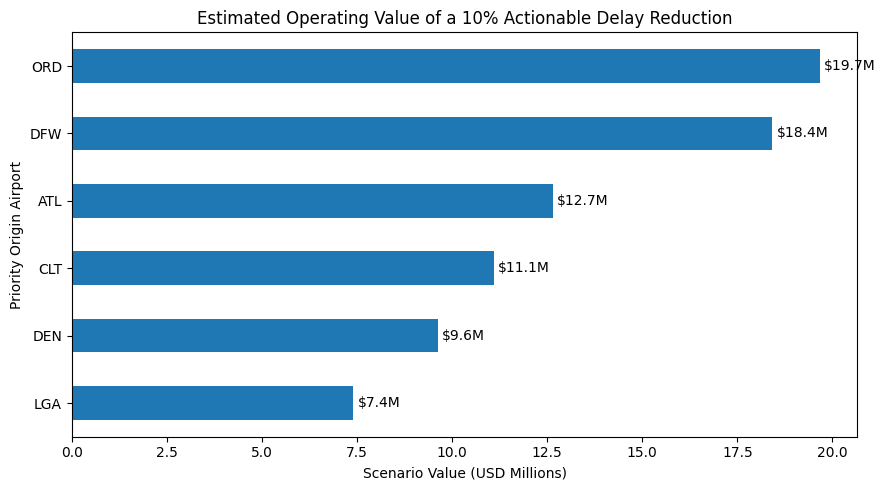

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\figures\airport_financial_impact_base_case.png


In [10]:
airport_plot_df = (
    airport_base_case
    .sort_values(
        "estimated_value_millions",
        ascending=True
    )
)

ax = airport_plot_df["estimated_value_millions"].plot(
    kind="barh",
    figsize=(9, 5)
)

ax.set_title(
    "Estimated Operating Value of a 10% Actionable Delay Reduction"
)
ax.set_xlabel(
    "Scenario Value (USD Millions)"
)
ax.set_ylabel(
    "Priority Origin Airport"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="$%.1fM",
        padding=3
    )

plt.tight_layout()

output_path = (
    figures_dir
    / "airport_financial_impact_base_case.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

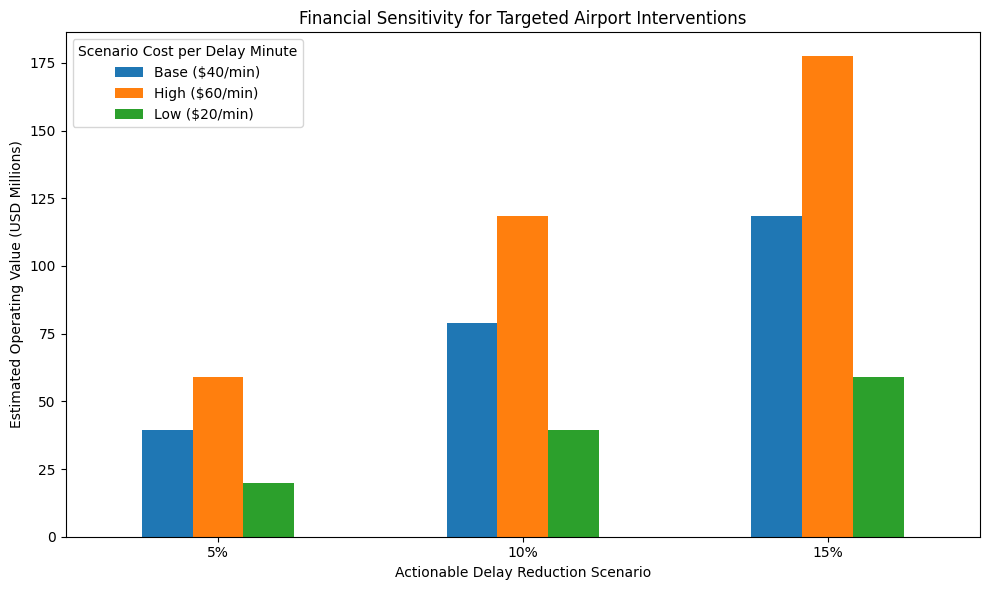

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\figures\targeted_financial_sensitivity.png


In [11]:
targeted_financial_plot = (
    financial_scenarios[
        financial_scenarios["scope"] == "Targeted 6 Airports"
    ]
    .pivot(
        index="reduction_scenario",
        columns="cost_assumption",
        values="estimated_operating_value_millions"
    )
    .reindex(["5%", "10%", "15%"])
)

ax = targeted_financial_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title(
    "Financial Sensitivity for Targeted Airport Interventions"
)
ax.set_xlabel(
    "Actionable Delay Reduction Scenario"
)
ax.set_ylabel(
    "Estimated Operating Value (USD Millions)"
)

ax.legend(
    title="Scenario Cost per Delay Minute"
)

plt.xticks(rotation=0)
plt.tight_layout()

output_path = (
    figures_dir
    / "targeted_financial_sensitivity.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

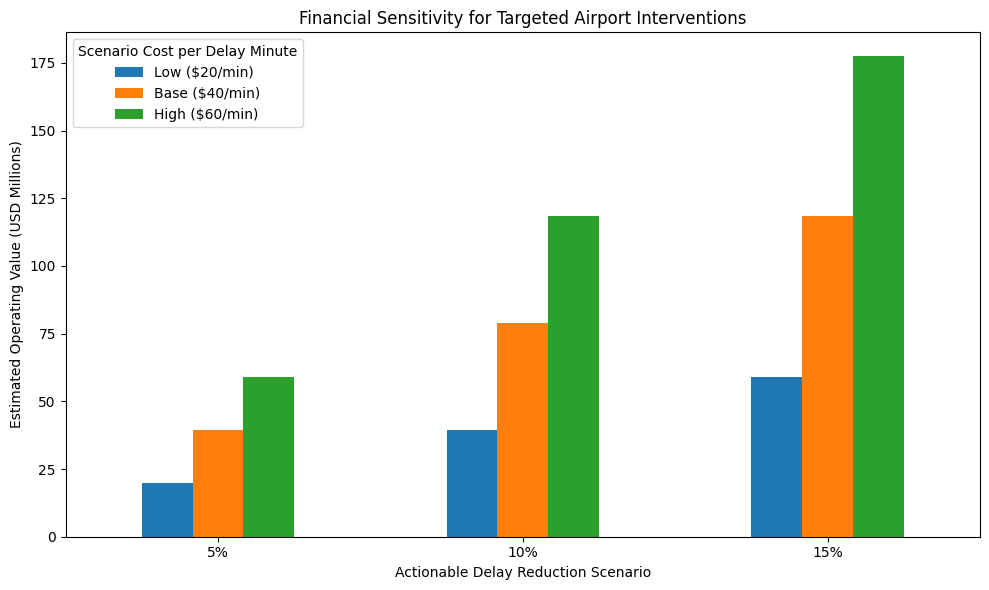

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\figures\targeted_financial_sensitivity.png


In [12]:
targeted_financial_plot = (
    financial_scenarios[
        financial_scenarios["scope"] == "Targeted 6 Airports"
    ]
    .pivot(
        index="reduction_scenario",
        columns="cost_assumption",
        values="estimated_operating_value_millions"
    )
    .reindex(["5%", "10%", "15%"])
)

targeted_financial_plot = targeted_financial_plot[
    [
        "Low ($20/min)",
        "Base ($40/min)",
        "High ($60/min)"
    ]
]

ax = targeted_financial_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

ax.set_title(
    "Financial Sensitivity for Targeted Airport Interventions"
)
ax.set_xlabel(
    "Actionable Delay Reduction Scenario"
)
ax.set_ylabel(
    "Estimated Operating Value (USD Millions)"
)

ax.legend(
    title="Scenario Cost per Delay Minute"
)

plt.xticks(rotation=0)
plt.tight_layout()

output_path = (
    figures_dir
    / "targeted_financial_sensitivity.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {output_path}")

In [13]:
day6_findings = """# Day 6 - Intervention Prioritization & Financial Impact

## 1. Operationally Actionable Delay Baseline

Total attributed delay minutes in the analytical dataset:

76,925,980 minutes

For intervention analysis, operationally actionable delay is defined as:

Carrier Delay + Late Aircraft Delay

Observed baseline:

- Operationally actionable delay minutes: 54,619,827
- Operationally actionable share: 71.00%
- External / system delay minutes: 22,306,153
- External / system share: 29.00%

The 71% figure represents the observed share of delay minutes associated with Carrier Delay and Late Aircraft Delay.

It should not be interpreted as the percentage of delay that can be fully eliminated.

## 2. Airport Intervention Opportunities

The largest actionable delay opportunity pools among the selected core airports include:

- ORD: 4.92 million actionable delay minutes
- DFW: 4.60 million
- ATL: 3.16 million
- CLT: 2.77 million
- DEN: 2.41 million
- LGA: 1.85 million

ORD and DFW combine large delay exposure with high actionable delay intensity.

EWR and LGA have smaller absolute volumes than ORD and DFW but relatively high actionable delay intensity.

## 3. Route-Level Opportunities

High-opportunity routes were identified using:

- minimum annual flight volume
- delay rate
- actionable delay minutes
- actionable delay intensity
- actionable share

Examples include:

- LGA → ORD
- ORD → LGA
- DFW → ORD
- ORD → DFW
- DFW → SAT
- ORD → MKE
- ORD → STL
- LAX → DFW
- IAH → DFW

The analysis supports targeted route-level interventions rather than uniform network-wide schedule changes.

## 4. Recommended Intervention Framework

### Aircraft Rotation Recovery

Target:
High-propagation airports and aircraft rotations.

Actions may include:

- proactive recovery of delayed inbound aircraft
- protection of downstream rotations
- aircraft swaps where operationally feasible
- additional recovery resources following severe upstream delays

Evidence:
Previous-flight delays increased next-flight delay risk from 13.82% to 48.41%.

### Targeted Turnaround Support

Target:
High-volume operational hubs such as ORD, DFW, ATL, CLT and DEN.

Potential actions:

- targeted gate support
- ground-handling prioritization
- baggage and fueling coordination
- turnaround recovery resources for high-risk flights

### Route-Specific Schedule Buffer Review

Target:
Repeated high-intensity routes.

Potential actions:

- review scheduled block time
- review turnaround buffers
- identify recurring structural schedule pressure

This recommendation does not imply system-wide schedule padding.

### High-Risk Flight Watchlist

Target:
Flights identified by the pre-flight XGBoost model.

Potential actions:

- proactive monitoring
- recovery preparation
- prioritized operational attention
- resource allocation to higher-risk departures

The final model produced a 1.32x risk lift on the December out-of-time test set.

## 5. Delay Reduction Scenarios

Scenario reductions of 5%, 10% and 15% were applied to operationally actionable delay minutes.

These are scenario assumptions and not observed reductions.

### Network-Wide Scenario

Baseline actionable delay minutes:

54,619,827

Estimated delay minutes avoided:

- 5% reduction: 2,730,991 minutes
- 10% reduction: 5,461,983 minutes
- 15% reduction: 8,192,974 minutes

### Targeted Six-Airport Scenario

Priority airports:

ORD, DFW, ATL, DEN, CLT and LGA

Baseline actionable delay minutes:

19,713,632

Estimated delay minutes avoided:

- 5% reduction: 985,682 minutes
- 10% reduction: 1,971,363 minutes
- 15% reduction: 2,957,045 minutes

## 6. Financial Sensitivity Assumptions

Because the BTS dataset does not identify the exact operational phase of each arrival-delay minute, a single observed airline cost per delay minute cannot be derived directly.

The financial analysis therefore uses explicit scenario assumptions:

- Low: $20 per avoided delay minute
- Base: $40 per avoided delay minute
- High: $60 per avoided delay minute

These values are sensitivity assumptions rather than realized airline financial results.

## 7. Network-Wide Scenario Value

Under the Base assumption of $40 per avoided delay minute:

- 5% reduction: $109.24 million
- 10% reduction: $218.48 million
- 15% reduction: $327.72 million

These figures represent estimated scenario operating value rather than guaranteed cost savings.

## 8. Targeted Six-Airport Scenario Value

Under the Base assumption of:

10% actionable delay reduction
and
$40 per avoided delay minute

the six-airport scenario produces:

- Delay minutes avoided: approximately 1.97 million
- Estimated operating value: approximately $78.85 million

Airport-level scenario values:

- ORD: $19.67 million
- DFW: $18.42 million
- ATL: $12.65 million
- CLT: $11.09 million
- DEN: $9.63 million
- LGA: $7.40 million

## 9. Business Recommendation

The recommended strategy is targeted rather than network-wide.

Priority should be given to airports and routes that combine:

- large operational exposure
- high actionable delay minutes
- strong delay propagation
- elevated actionable delay intensity

A practical intervention sequence would be:

1. Prioritize ORD and DFW as major propagation and actionable-delay nodes.
2. Expand targeted recovery support to ATL, DEN, CLT and LGA.
3. Review recurring high-intensity routes for schedule and turnaround pressure.
4. Use the pre-flight XGBoost model to identify higher-risk flights for targeted operational attention.
5. Measure realized delay-minute reductions before translating scenario value into financial claims.

## Interpretation Note

All financial values in this analysis are scenario-based estimates.

They should not be interpreted as actual airline profit, realized cost savings, or guaranteed financial outcomes.
"""

docs_dir = project_root / "docs"
docs_dir.mkdir(parents=True, exist_ok=True)

findings_path = docs_dir / "day6_intervention_findings.md"

findings_path.write_text(
    day6_findings,
    encoding="utf-8"
)

print(f"Saved to: {findings_path}")

Saved to: C:\Users\21129\Documents\airline-delay-reliability-analysis\docs\day6_intervention_findings.md
